# Predicting Smartphone Price Tier From Hardware Specifications Using Machine Learning
### Mobiles Dataset (2025) | Random Forest vs Gradient Boosting | Google Colab Notebook

**Goal:** classify each phone as **Budget**, **Mid-Range** or **Premium** using only its hardware specs (RAM, storage, battery, cameras, weight, screen, processor, brand, launch year).

**Pipeline (KDD):** Selection -> Preprocessing -> Transformation -> EDA -> Modeling (2 classifiers) -> Evaluation.

**How to run in Colab:** run the cells top to bottom. Cell 3 opens a file picker: upload `Mobiles_Dataset__2025_.csv`.

## 1. Environment Setup

In [1]:
import os, re, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)

print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Seaborn      :", sns.__version__)

NumPy        : 2.4.4
Pandas       : 3.0.2
Scikit-learn : 1.8.0
Seaborn      : 0.13.2


In [2]:
# Output folders + plot style + tier colours
OUT_DIR = Path("/content/outputs") if Path("/content").exists() else Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "axes.titlesize": 13, "axes.labelsize": 11, "grid.alpha": 0.35, "grid.linestyle": "--"})

TIER_ORDER  = ["Budget", "Mid-Range", "Premium"]
TIER_COLORS = {"Budget": "#2b8cbe", "Mid-Range": "#f39c12", "Premium": "#c0392b"}
print("Output directory:", OUT_DIR.resolve())

Output directory: /content/outputs


## 2. Data Loading

In [3]:
CSV_NAME = "Mobiles_Dataset__2025_.csv"

def locate_csv():
    for p in [Path(CSV_NAME), Path("/content") / CSV_NAME, Path("/content/drive/MyDrive") / CSV_NAME]:
        if p.exists():
            return p
    from google.colab import files          # opens the upload dialog in Colab
    print("Please upload", CSV_NAME)
    uploaded = files.upload()
    return Path(list(uploaded.keys())[0])

csv_path = locate_csv()
try:
    df_raw = pd.read_csv(csv_path, encoding="utf-8")
except UnicodeDecodeError:
    df_raw = pd.read_csv(csv_path, encoding="latin1")

print(f"Loaded: {csv_path}")
print(f"Shape : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded: Mobiles_Dataset__2025_.csv
Shape : 930 rows x 15 columns


,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (Pakistan),Launched Price (India),Launched Price (China),Launched Price (USA),Launched Price (Dubai),Launched Year
0,Apple,iPhone 16 128GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 224,999","INR 79,999","CNY 5,799",USD 799,"AED 2,799",2024
1,Apple,iPhone 16 256GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 234,999","INR 84,999","CNY 6,099",USD 849,"AED 2,999",2024
2,Apple,iPhone 16 512GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 244,999","INR 89,999","CNY 6,499",USD 899,"AED 3,199",2024
3,Apple,iPhone 16 Plus 128GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 249,999","INR 89,999","CNY 6,199",USD 899,"AED 3,199",2024
4,Apple,iPhone 16 Plus 256GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 259,999","INR 94,999","CNY 6,499",USD 949,"AED 3,399",2024


In [4]:
# Quick data audit: types, missing values, duplicates
print("Column data types:")
print(df_raw.dtypes.to_string())
print("\nTotal missing values :", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows :", int(df_raw.duplicated().sum()))
print("\nUnique values per column:")
print(df_raw.nunique().to_string())

Column data types:
Company Name                   str
Model Name                     str
Mobile Weight                  str
RAM                            str
Front Camera                   str
Back Camera                    str
Processor                      str
Battery Capacity               str
Screen Size                    str
Launched Price (Pakistan)      str
Launched Price (India)         str
Launched Price (China)         str
Launched Price (USA)           str
Launched Price (Dubai)         str
Launched Year                int64

Total missing values : 0
Exact duplicate rows : 15

Unique values per column:
Company Name                  19
Model Name                   908
Mobile Weight                148
RAM                           11
Front Camera                  29
Back Camera                   91
Processor                    217
Battery Capacity             147
Screen Size                   97
Launched Price (Pakistan)    157
Launched Price (India)       147
Launched Price

## 3. Preprocessing
Most columns are text (`"3,600mAh"`, `"50MP + 12MP"`, `"6.1 inches"`). We convert them into numeric features.

In [5]:
def first_number(x):
    """First numeric value in a string: '3,600mAh' -> 3600.0"""
    m = re.search(r"\d[\d,]*\.?\d*", str(x))
    return float(m.group().replace(",", "")) if m else np.nan

def mp_values(x):
    """All 'NNMP' values in a camera string -> list of floats"""
    return [float(v) for v in re.findall(r"(\d+\.?\d*)\s*MP", str(x), flags=re.I)]

def processor_family(p):
    p = str(p).lower()
    if re.match(r"^a\d{2}", p):
        return "apple"
    rules = [("snapdragon", ["snapdragon", "qualcomm"]), ("dimensity", ["dimensity"]),
             ("mediatek helio/other", ["mediatek", "helio"]), ("exynos", ["exynos"]),
             ("kirin", ["kirin"]), ("tensor", ["tensor", "google"]), ("unisoc", ["unisoc", "spreadtrum"])]
    for fam, keys in rules:
        if any(k in p for k in keys):
            return fam
    return "other"

def storage_from_name(name):
    """Largest 'NNNGB' / 'N TB' in the model name: 'iPhone 16 256GB' -> 256"""
    vals = [float(n) * (1024 if u.upper() == "TB" else 1)
            for n, u in re.findall(r"(\d+)\s*(GB|TB)", str(name), flags=re.I)]
    return max(vals) if vals else np.nan

# quick sanity test of the helpers
print(first_number("3,600mAh"), "|", mp_values("50MP + 12MP (ultrawide)"), "|",
      processor_family("Snapdragon 8 Gen 2"), "|", storage_from_name("iPhone 16 Pro 256GB"))

3600.0 | [50.0, 12.0] | snapdragon | 256.0


In [6]:
df = df_raw.drop_duplicates().reset_index(drop=True).copy()
df["Company Name"] = (df["Company Name"].str.strip().str.title()
                      .replace({"Iqoo": "iQOO", "Oneplus": "OnePlus", "Poco": "POCO"}))

df["weight_g"]      = df["Mobile Weight"].map(first_number)
df["ram_gb"]        = df["RAM"].map(first_number)
df["front_mp"]      = df["Front Camera"].map(first_number)
back                = df["Back Camera"].map(mp_values)
df["back_main_mp"]  = back.map(lambda l: l[0] if l else np.nan)
df["back_total_mp"] = back.map(lambda l: sum(l) if l else np.nan)
df["n_back_cams"]   = back.map(len)
df["battery_mah"]   = df["Battery Capacity"].map(first_number)
df["screen_in"]     = df["Screen Size"].map(first_number)
df["storage_gb"]    = df["Model Name"].map(storage_from_name)
df["launch_year"]   = df["Launched Year"]
df["proc_family"]   = df["Processor"].map(processor_family)
df["brand"]         = df["Company Name"]

price_cols = {"Launched Price (Pakistan)": "price_pkr", "Launched Price (India)": "price_inr",
              "Launched Price (China)": "price_cny", "Launched Price (USA)": "price_usd",
              "Launched Price (Dubai)": "price_aed"}
for old, new in price_cols.items():
    df[new] = df[old].map(first_number)

NUM_FEATURES = ["weight_g", "ram_gb", "front_mp", "back_main_mp", "back_total_mp",
                "n_back_cams", "battery_mah", "screen_in", "storage_gb", "launch_year"]

print(f"Rows after removing duplicates: {len(df)}  (removed {len(df_raw) - len(df)})")
print("\nMissing values after parsing:")
print(df[NUM_FEATURES].isna().sum().to_string())

Rows after removing duplicates: 915  (removed 15)

Missing values after parsing:
weight_g           0
ram_gb             0
front_mp           0
back_main_mp       0
back_total_mp      0
n_back_cams        0
battery_mah        0
screen_in          0
storage_gb       152
launch_year        0


In [7]:
# Fill the gaps (storage not mentioned in model name) with the column median
for c in NUM_FEATURES:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())

print(f"Clean dataset: {df.shape[0]} unique phones, {df['brand'].nunique()} brands")
print("Processor families:", df["proc_family"].value_counts().to_dict())
display(df[NUM_FEATURES + ["price_usd"]].describe().round(2).T)

Clean dataset: 915 unique phones, 18 brands
Processor families: {'snapdragon': 364, 'dimensity': 209, 'mediatek helio/other': 120, 'apple': 97, 'exynos': 47, 'unisoc': 34, 'kirin': 31, 'tensor': 13}


,count,mean,std,min,25%,50%,75%,max
weight_g,915.0,228.91,106.16,135.0,185.0,195.00,209.00,732.0
ram_gb,915.0,7.79,3.19,1.0,6.0,8.00,8.00,16.0
front_mp,915.0,18.17,12.04,2.0,8.0,16.00,32.00,60.0
back_main_mp,915.0,46.49,31.12,5.0,13.0,50.00,50.00,200.0
back_total_mp,915.0,55.26,36.97,5.0,24.0,50.00,64.00,212.0
n_back_cams,915.0,1.62,0.79,1.0,1.0,1.00,2.00,4.0
battery_mah,915.0,5030.28,1365.57,2000.0,4400.0,5000.00,5100.00,11200.0
screen_in,915.0,7.09,1.54,5.0,6.5,6.67,6.78,14.6
storage_gb,915.0,199.40,146.28,16.0,128.0,128.00,256.00,2048.0
launch_year,915.0,2022.21,1.87,2014.0,2021.0,2023.00,2024.00,2025.0


## 4. Target Formulation and Feature Matrix
The USD launch price is split into **three equal-sized groups** (tertiles): Budget, Mid-Range and Premium.
All five price columns are **excluded** from the features to avoid target leakage.

In [8]:
q1, q2 = df["price_usd"].quantile([1/3, 2/3])
df["price_tier"] = pd.cut(df["price_usd"], bins=[-np.inf, q1, q2, np.inf], labels=TIER_ORDER)

print(f"Tier thresholds (USD): Budget <= {q1:.0f} < Mid-Range <= {q2:.0f} < Premium")
display(df["price_tier"].value_counts().reindex(TIER_ORDER).to_frame("phones"))

Tier thresholds (USD): Budget <= 310 < Mid-Range <= 699 < Premium


,phones
price_tier,
Budget,305
Mid-Range,325
Premium,285


In [9]:
X = pd.concat([df[NUM_FEATURES],
               pd.get_dummies(df["brand"], prefix="brand"),
               pd.get_dummies(df["proc_family"], prefix="cpu")], axis=1).astype(float)
y = df["price_tier"].map({t: i for i, t in enumerate(TIER_ORDER)}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)

print(f"Feature matrix : {X.shape[0]} rows x {X.shape[1]} features "
      f"({len(NUM_FEATURES)} numeric + {X.shape[1]-len(NUM_FEATURES)} one-hot)")
print(f"Train / Test   : {len(X_train)} / {len(X_test)}")
print("Train class mix:", y_train.map(dict(enumerate(TIER_ORDER))).value_counts().to_dict())
print("Test  class mix:", y_test.map(dict(enumerate(TIER_ORDER))).value_counts().to_dict())

Feature matrix : 915 rows x 36 features (10 numeric + 26 one-hot)
Train / Test   : 732 / 183
Train class mix: {'Mid-Range': 260, 'Budget': 244, 'Premium': 228}
Test  class mix: {'Mid-Range': 65, 'Budget': 61, 'Premium': 57}


## 5. Exploratory Data Analysis (Graphs 1-3)

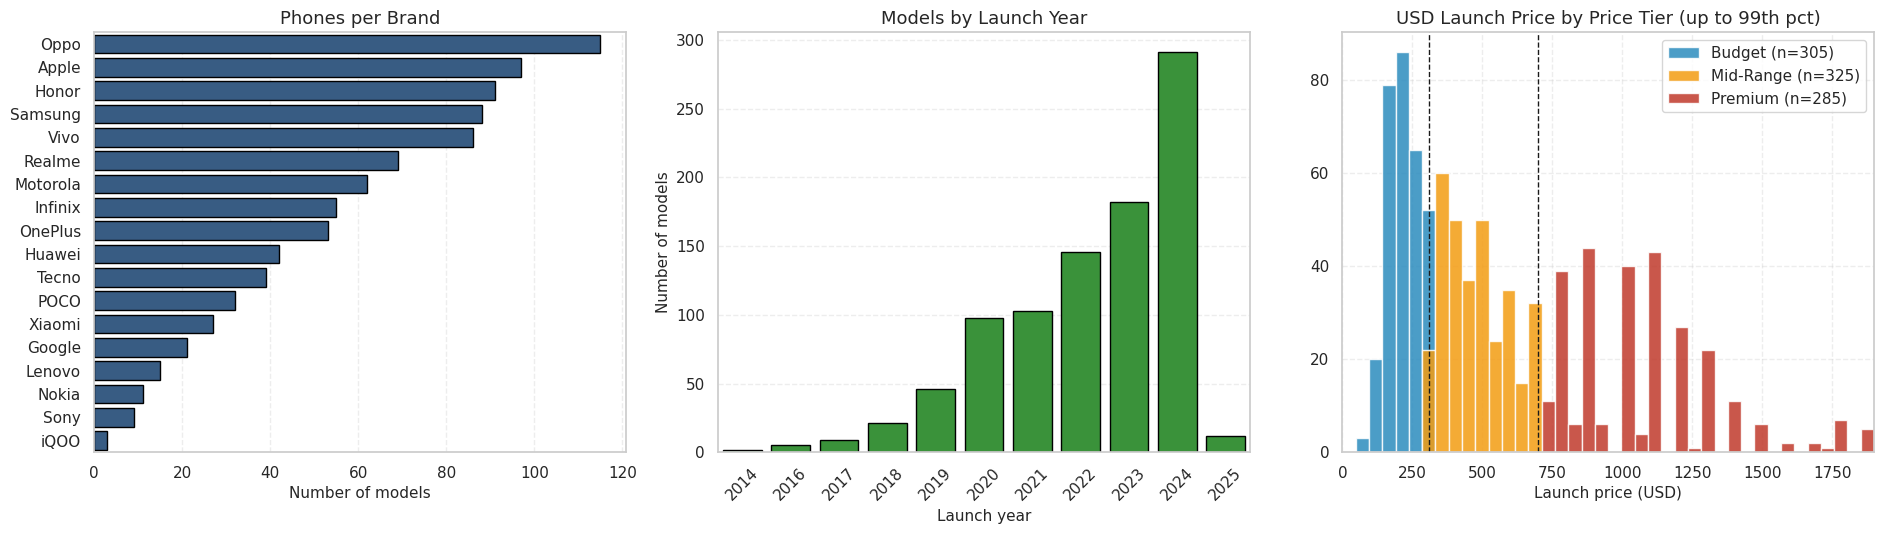

In [10]:
# GRAPH 1: Dataset overview
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

bc = df["brand"].value_counts()
sns.barplot(x=bc.values, y=bc.index, color="#2b5c8f", edgecolor="black", ax=axes[0])
axes[0].set_title("Phones per Brand"); axes[0].set_xlabel("Number of models"); axes[0].set_ylabel("")

yc = df["launch_year"].value_counts().sort_index()
sns.barplot(x=yc.index.astype(int), y=yc.values, color="#2ca02c", edgecolor="black", ax=axes[1])
axes[1].set_title("Models by Launch Year"); axes[1].set_xlabel("Launch year"); axes[1].set_ylabel("Number of models")
axes[1].tick_params(axis="x", rotation=45)

cap = df["price_usd"].quantile(0.99)
bins = np.linspace(0, cap, 41)                      # same bins for every tier
for t in TIER_ORDER:
    axes[2].hist(df.loc[(df["price_tier"] == t) & (df["price_usd"] <= cap), "price_usd"], bins=bins,
                 color=TIER_COLORS[t], alpha=0.85, edgecolor="white", label=f"{t} (n={int((df['price_tier']==t).sum())})")
axes[2].axvline(q1, color="k", ls="--", lw=1); axes[2].axvline(q2, color="k", ls="--", lw=1)
axes[2].set_xlim(0, cap)
axes[2].set_title("USD Launch Price by Price Tier (up to 99th pct)")
axes[2].set_xlabel("Launch price (USD)"); axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_dataset_overview.png"); plt.show()

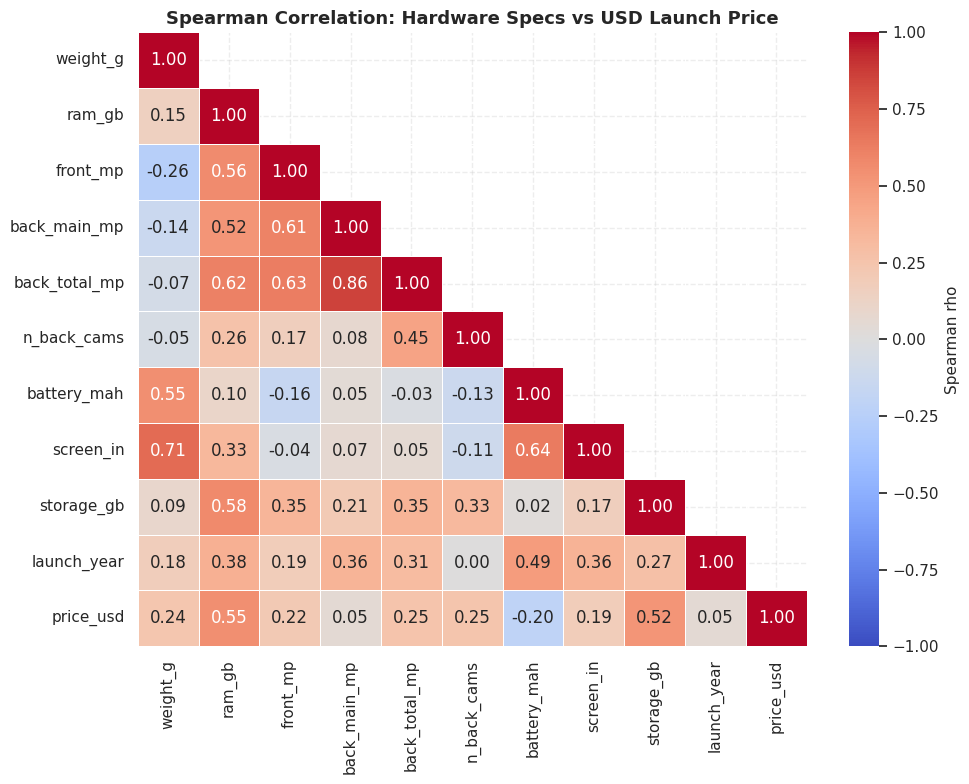

Rank correlation with USD price:
ram_gb           0.550
storage_gb       0.520
back_total_mp    0.252
n_back_cams      0.249
weight_g         0.236
front_mp         0.216
screen_in        0.186
back_main_mp     0.054
launch_year      0.050
battery_mah     -0.203


In [11]:
# GRAPH 2: Spearman correlation heatmap
corr = df[NUM_FEATURES + ["price_usd"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Spearman rho"})
plt.title("Spearman Correlation: Hardware Specs vs USD Launch Price", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_correlation_heatmap.png"); plt.show()

print("Rank correlation with USD price:")
print(corr["price_usd"].drop("price_usd").sort_values(ascending=False).round(3).to_string())

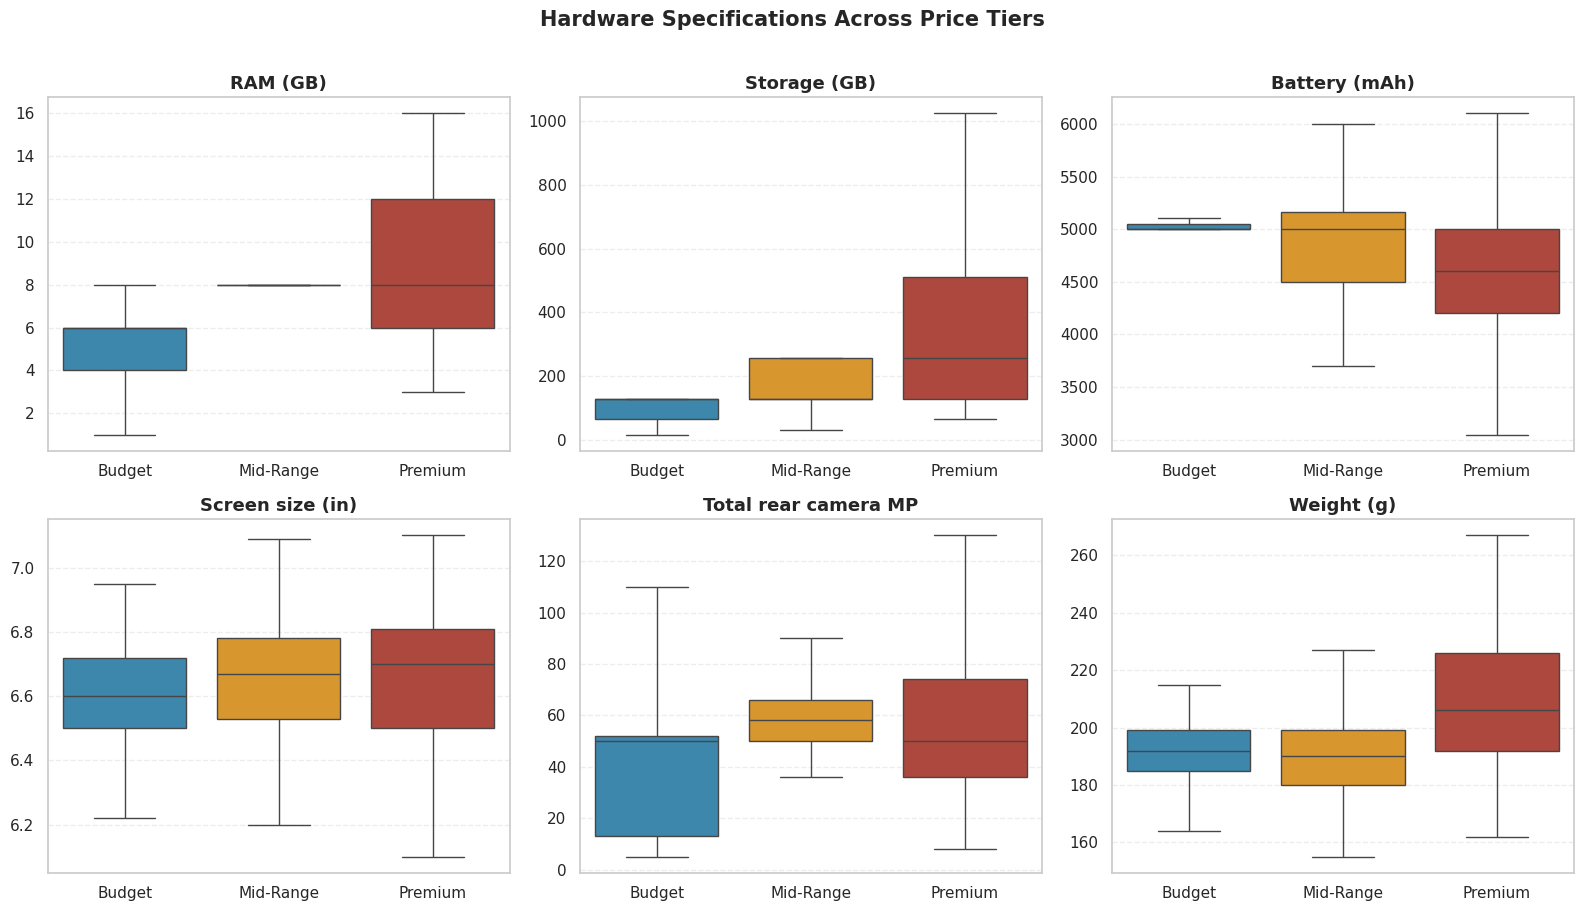

In [12]:
# GRAPH 3: Key specs by price tier
box_feats = [("ram_gb", "RAM (GB)"), ("storage_gb", "Storage (GB)"), ("battery_mah", "Battery (mAh)"),
             ("screen_in", "Screen size (in)"), ("back_total_mp", "Total rear camera MP"), ("weight_g", "Weight (g)")]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, label) in zip(axes.ravel(), box_feats):
    sns.boxplot(data=df, x="price_tier", y=col, order=TIER_ORDER, palette=TIER_COLORS, showfliers=False, ax=ax)
    ax.set_title(label, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Hardware Specifications Across Price Tiers", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_specs_by_price_tier.png"); plt.show()

In [13]:
# Statistical test: do the specs differ across the three tiers? (Kruskal-Wallis, non-parametric)
rows = []
for col in NUM_FEATURES:
    groups = [df.loc[df["price_tier"] == t, col] for t in TIER_ORDER]
    h, p = stats.kruskal(*groups)
    rows.append({"feature": col, "Budget median": groups[0].median(), "Mid-Range median": groups[1].median(),
                 "Premium median": groups[2].median(), "H statistic": round(h, 1),
                 "p-value": f"{p:.2e}", "significant (p<0.001)": p < 0.001})
display(pd.DataFrame(rows).set_index("feature"))

,Budget median,Mid-Range median,Premium median,H statistic,p-value,significant (p<0.001)
feature,,,,,,
weight_g,192.0,190.00,206.0,87.0,1.31e-19,True
ram_gb,6.0,8.00,8.0,265.2,2.64e-58,True
front_mp,8.0,20.00,12.0,151.8,1.10e-33,True
back_main_mp,50.0,50.00,50.0,56.6,5.13e-13,True
back_total_mp,50.0,58.00,50.0,68.5,1.33e-15,True
n_back_cams,1.0,1.00,2.0,49.8,1.55e-11,True
battery_mah,5000.0,5000.00,4600.0,36.7,1.05e-08,True
screen_in,6.6,6.67,6.7,24.7,4.23e-06,True
storage_gb,128.0,128.00,256.0,223.8,2.55e-49,True


## 6. Model Training (2 Classifiers)
**Random Forest** and **Gradient Boosting**, each tuned with 5-fold stratified `GridSearchCV` optimising macro-F1.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
best_models, best_params = {}, {}

rf_grid = {"n_estimators": [200, 400], "max_depth": [None, 12], "min_samples_leaf": [1, 2]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1), rf_grid,
                     cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
best_models["Random Forest"], best_params["Random Forest"] = gs_rf.best_estimator_, gs_rf.best_params_

print("RANDOM FOREST")
print("  best params         :", gs_rf.best_params_)
print(f"  best CV macro-F1    : {gs_rf.best_score_:.4f}")

RANDOM FOREST
  best params         : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}
  best CV macro-F1    : 0.8582


In [15]:
gb_grid = {"n_estimators": [150, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_SEED), gb_grid,
                     cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
best_models["Gradient Boosting"], best_params["Gradient Boosting"] = gs_gb.best_estimator_, gs_gb.best_params_

print("GRADIENT BOOSTING")
print("  best params         :", gs_gb.best_params_)
print(f"  best CV macro-F1    : {gs_gb.best_score_:.4f}")

GRADIENT BOOSTING
  best params         : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
  best CV macro-F1    : 0.8640


## 7. Evaluation on the Held-Out Test Set

In [16]:
results, preds, probas = [], {}, {}
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

for name, model in best_models.items():
    y_pred, y_prob = model.predict(X_test), model.predict_proba(X_test)
    preds[name], probas[name] = y_pred, y_prob
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, y_pred),
                    "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
                    "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
                    "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
                    "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
                    "ROC-AUC (OvR)": roc_auc_score(y_test, y_prob, multi_class="ovr")})

df_results = pd.DataFrame(results).set_index("Model").round(4)
display(df_results)

,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,,
Random Forest,0.8361,0.8346,0.8597,0.8346,0.8409,0.9647
Gradient Boosting,0.8361,0.8367,0.8428,0.8367,0.8387,0.9490


In [17]:
for name in best_models:
    print("=" * 62)
    print("Classification report:", name)
    print("=" * 62)
    print(classification_report(y_test, preds[name], target_names=TIER_ORDER, digits=3))

Classification report: Random Forest
              precision    recall  f1-score   support

      Budget      0.923     0.787     0.850        61
   Mid-Range      0.716     0.892     0.795        65
     Premium      0.940     0.825     0.879        57

    accuracy                          0.836       183
   macro avg      0.860     0.835     0.841       183
weighted avg      0.855     0.836     0.839       183

Classification report: Gradient Boosting
              precision    recall  f1-score   support

      Budget      0.893     0.820     0.855        61
   Mid-Range      0.761     0.831     0.794        65
     Premium      0.875     0.860     0.867        57

    accuracy                          0.836       183
   macro avg      0.843     0.837     0.839       183
weighted avg      0.840     0.836     0.837       183



In [18]:
# 5-fold cross-validation on the full dataset with the tuned models (stability check)
cv_scores = {}
for name, model in best_models.items():
    cv_scores[name] = cross_val_score(model, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(f"{name:<18} fold scores: {np.round(cv_scores[name], 3)}  ->  "
          f"mean {cv_scores[name].mean():.4f} +/- {cv_scores[name].std():.4f}")

Random Forest      fold scores: [0.883 0.87  0.877 0.814 0.866]  ->  mean 0.8621 +/- 0.0246
Gradient Boosting  fold scores: [0.857 0.832 0.876 0.817 0.861]  ->  mean 0.8484 +/- 0.0211


## 8. Model Graphs (Graphs 4-7)

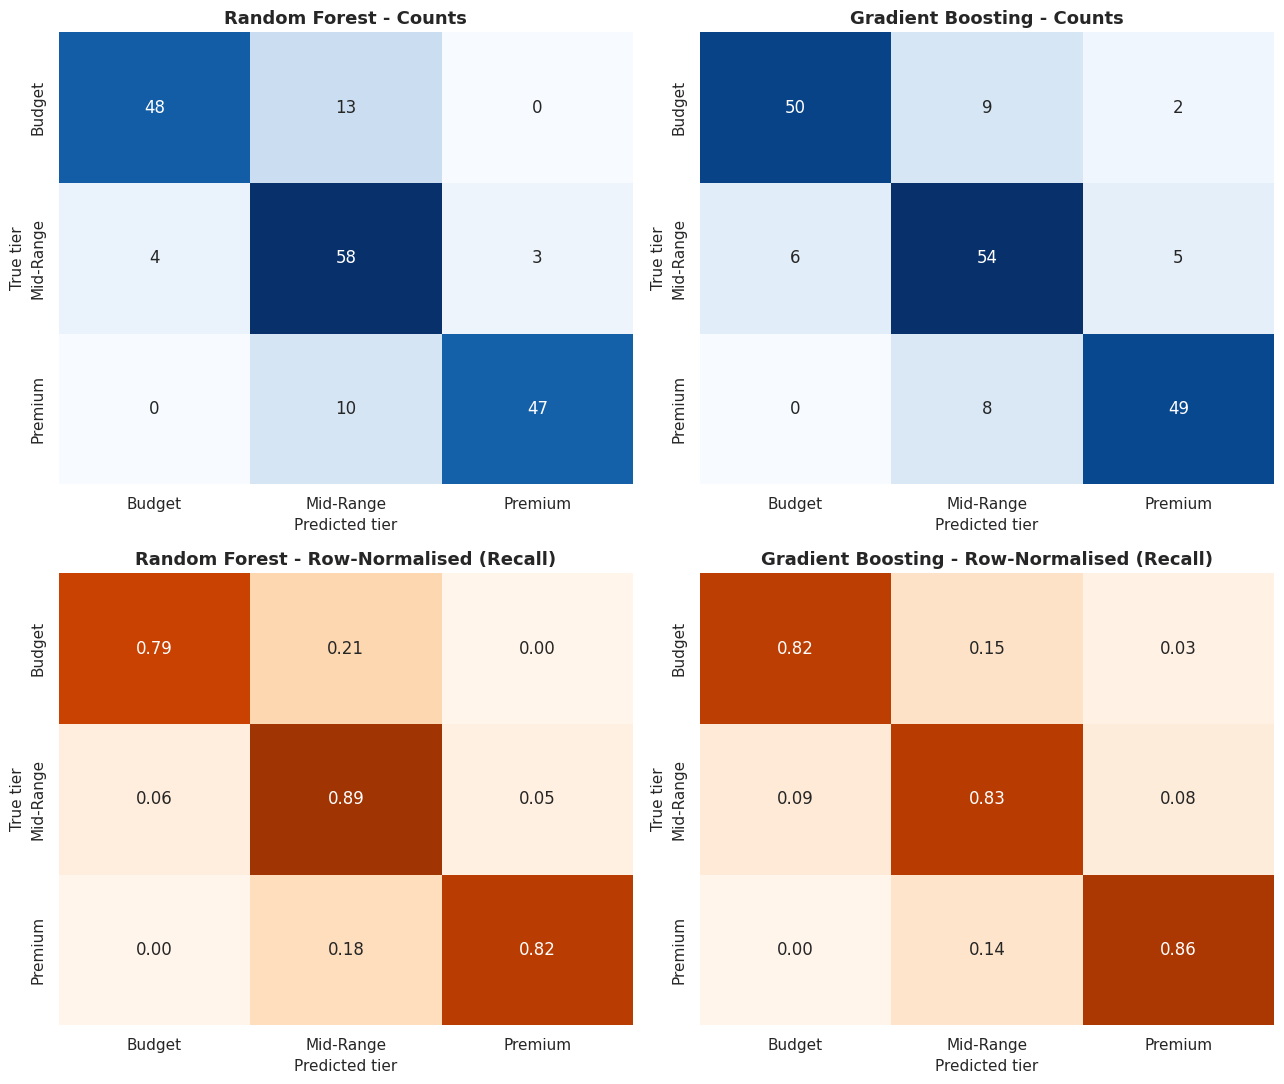

In [19]:
# GRAPH 4: Confusion matrices (counts and row-normalised)
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for j, name in enumerate(best_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TIER_ORDER, yticklabels=TIER_ORDER,
                cbar=False, ax=axes[0, j])
    axes[0, j].set_title(f"{name} - Counts", fontweight="bold")
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1,
                xticklabels=TIER_ORDER, yticklabels=TIER_ORDER, cbar=False, ax=axes[1, j])
    axes[1, j].set_title(f"{name} - Row-Normalised (Recall)", fontweight="bold")
    for i in range(2):
        axes[i, j].set_xlabel("Predicted tier"); axes[i, j].set_ylabel("True tier")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_confusion_matrices.png"); plt.show()

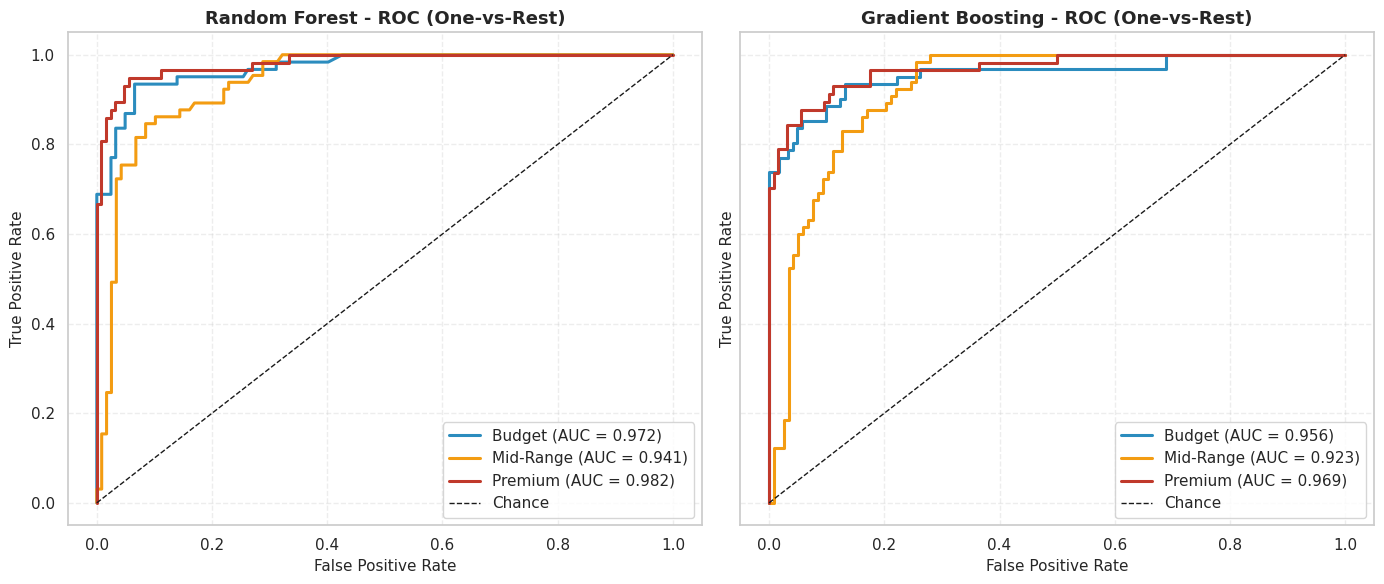

In [20]:
# GRAPH 5: One-vs-Rest ROC curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, name in zip(axes, best_models):
    for k, tier in enumerate(TIER_ORDER):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], probas[name][:, k])
        ax.plot(fpr, tpr, color=TIER_COLORS[tier], lw=2.2, label=f"{tier} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set_title(f"{name} - ROC (One-vs-Rest)", fontweight="bold")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_roc_curves.png"); plt.show()

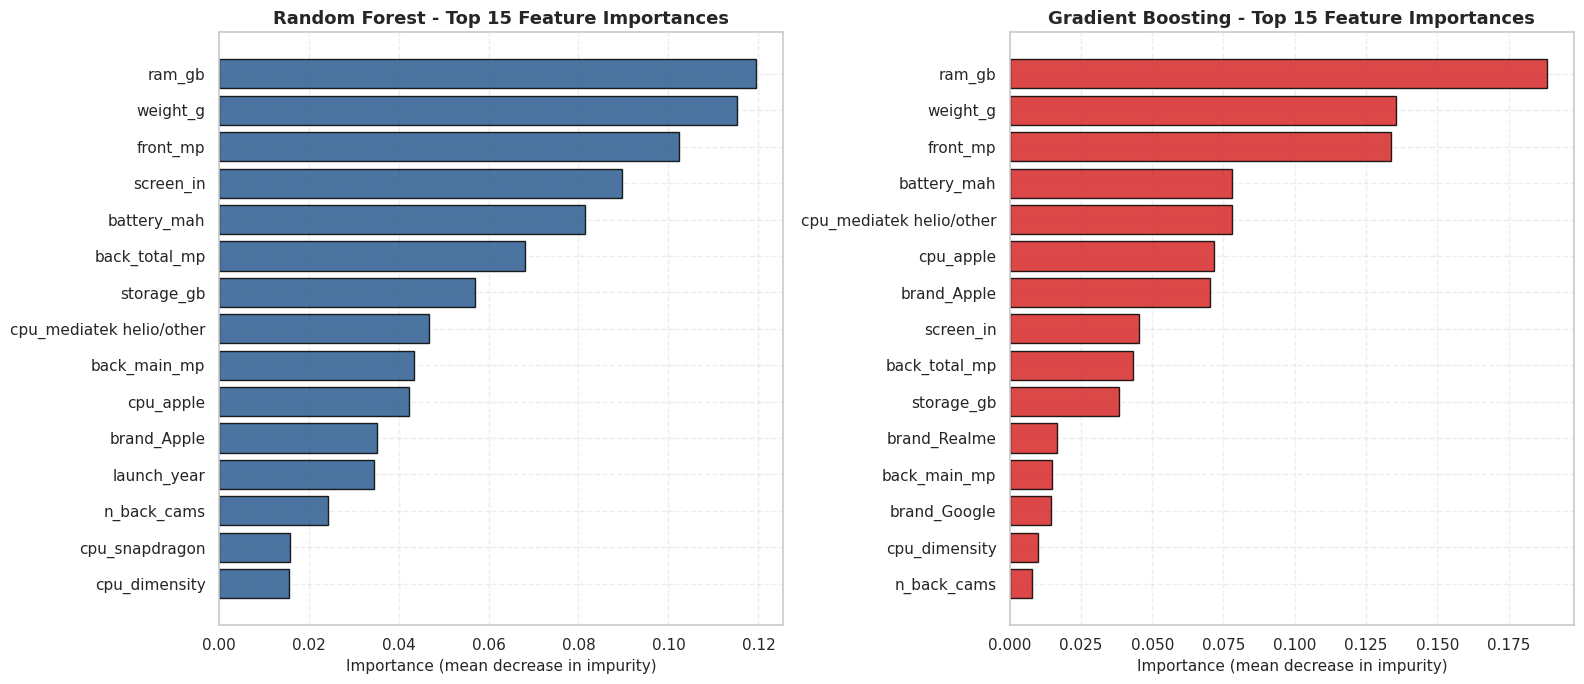

Top 8 features per model:


,Random Forest,Gradient Boosting
0,ram_gb (0.1195),ram_gb (0.1885)
1,weight_g (0.1153),weight_g (0.1354)
2,front_mp (0.1023),front_mp (0.1339)
3,screen_in (0.0897),battery_mah (0.078)
4,battery_mah (0.0815),cpu_mediatek helio/other (0.0779)
5,back_total_mp (0.0681),cpu_apple (0.0716)
6,storage_gb (0.057),brand_Apple (0.0704)
7,cpu_mediatek helio/other (0.0469),screen_in (0.0453)


In [21]:
# GRAPH 6: Top-15 feature importances
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
importance_tables = {}
for ax, (name, model) in zip(axes, best_models.items()):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    importance_tables[name] = imp
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color="#2b5c8f" if name == "Random Forest" else "#d62728",
            edgecolor="black", alpha=0.85)
    ax.set_title(f"{name} - Top 15 Feature Importances", fontweight="bold")
    ax.set_xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_feature_importance.png"); plt.show()

print("Top 8 features per model:")
display(pd.DataFrame({n: imp.head(8).round(4).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1)
                      for n, imp in importance_tables.items()}))

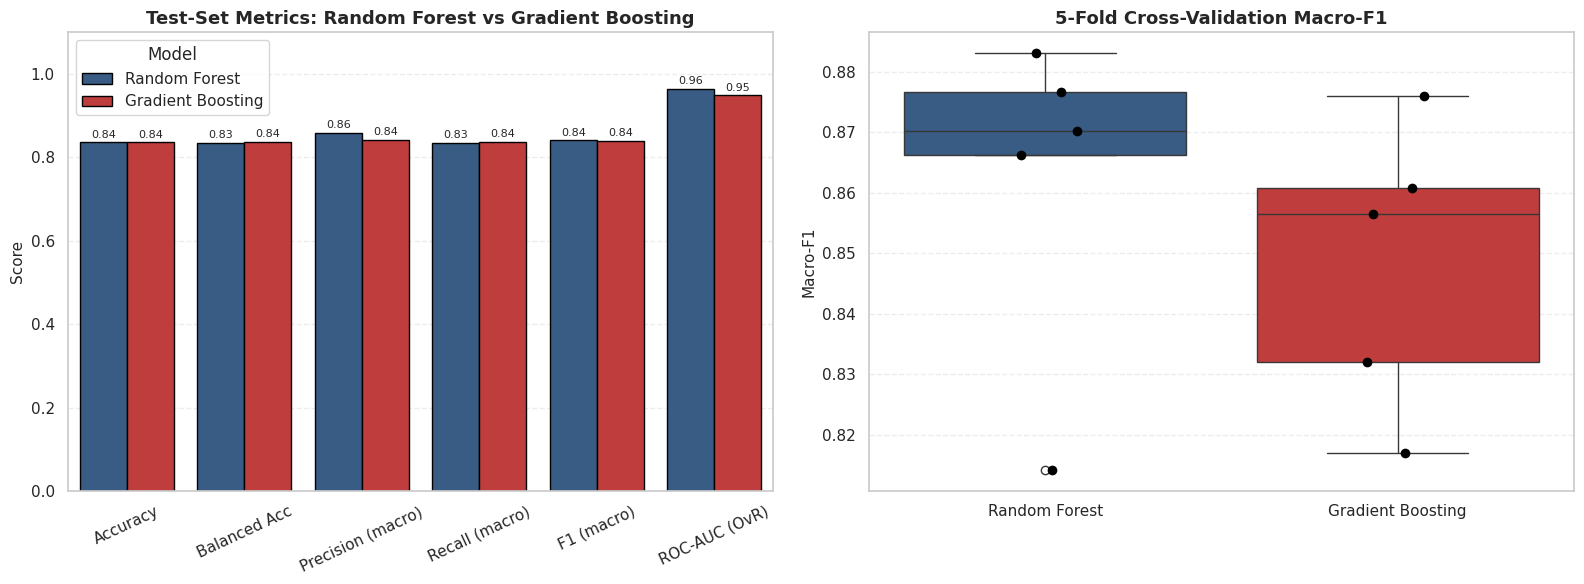

In [22]:
# GRAPH 7: Model comparison (test metrics + cross-validation stability)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

long = df_results.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(data=long, x="Metric", y="Score", hue="Model", palette=["#2b5c8f", "#d62728"], edgecolor="black", ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=8, padding=2)
axes[0].set_ylim(0, 1.1); axes[0].set_xlabel("")
axes[0].set_title("Test-Set Metrics: Random Forest vs Gradient Boosting", fontweight="bold")
axes[0].tick_params(axis="x", rotation=25)

cv_df = pd.DataFrame(cv_scores).melt(var_name="Model", value_name="Macro-F1")
sns.boxplot(data=cv_df, x="Model", y="Macro-F1", palette=["#2b5c8f", "#d62728"], ax=axes[1])
sns.stripplot(data=cv_df, x="Model", y="Macro-F1", color="black", size=7, ax=axes[1])
axes[1].set_title("5-Fold Cross-Validation Macro-F1", fontweight="bold"); axes[1].set_xlabel("")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig7_model_comparison.png"); plt.show()

## 9. Error Analysis and Saving Results

In [23]:
# Sample of test phones: true tier vs both models' predictions
sample = df.loc[X_test.index, ["brand", "Model Name", "price_usd", "price_tier"]].copy()
sample["RF prediction"] = pd.Series(preds["Random Forest"], index=X_test.index).map(dict(enumerate(TIER_ORDER)))
sample["GB prediction"] = pd.Series(preds["Gradient Boosting"], index=X_test.index).map(dict(enumerate(TIER_ORDER)))
display(sample.head(12))

wrong = (sample["RF prediction"] != sample["price_tier"]) | (sample["GB prediction"] != sample["price_tier"])
both_wrong = (sample["RF prediction"] != sample["price_tier"]) & (sample["GB prediction"] != sample["price_tier"])
print(f"Test phones misclassified by at least one model: {int(wrong.sum())} / {len(sample)}")
print(f"Test phones misclassified by BOTH models        : {int(both_wrong.sum())} / {len(sample)}")

,brand,Model Name,price_usd,price_tier,RF prediction,GB prediction
384,Oppo,Reno9 Pro+ 5G 256GB,649.0,Mid-Range,Mid-Range,Mid-Range
27,Apple,iPhone 14 Plus 128GB,899.0,Premium,Premium,Premium
624,Huawei,Nova 10 Pro,599.0,Mid-Range,Mid-Range,Mid-Range
914,Samsung,Galaxy Z Fold6 1TB,2259.0,Premium,Premium,Premium
545,Lenovo,K10 Note 64GB,219.0,Budget,Budget,Budget
422,Oppo,K11x 128GB,199.0,Budget,Budget,Budget
401,Oppo,Reno5 Pro+ 5G 256GB,599.0,Mid-Range,Mid-Range,Mid-Range
865,Honor,Pad 9,399.0,Mid-Range,Mid-Range,Mid-Range
817,Honor,Play 6T,229.0,Budget,Budget,Budget
34,Apple,iPhone 14 Pro Max 256GB,1299.0,Premium,Premium,Premium


Test phones misclassified by at least one model: 34 / 183
Test phones misclassified by BOTH models        : 26 / 183


In [24]:
df.drop(columns=list(price_cols.keys())).to_csv(OUT_DIR / "mobiles_clean_features.csv", index=False)
df_results.to_csv(OUT_DIR / "model_results.csv")
pd.DataFrame(cv_scores).to_csv(OUT_DIR / "cv_scores.csv", index=False)
for name, imp in importance_tables.items():
    imp.rename("importance").to_csv(OUT_DIR / f"feature_importance_{name.replace(' ', '_').lower()}.csv")

print("Saved files:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUT_DIR)):<45} {p.stat().st_size/1024:8.1f} KB")

Saved files:
  cv_scores.csv                                      0.2 KB
  feature_importance_gradient_boosting.csv           1.2 KB
  feature_importance_random_forest.csv               1.2 KB
  figures/fig1_dataset_overview.png                309.4 KB
  figures/fig2_correlation_heatmap.png             422.8 KB
  figures/fig3_specs_by_price_tier.png             290.7 KB
  figures/fig4_confusion_matrices.png              292.9 KB
  figures/fig5_roc_curves.png                      269.2 KB
  figures/fig6_feature_importance.png              323.4 KB
  figures/fig7_model_comparison.png                294.1 KB
  mobiles_clean_features.csv                       182.0 KB
  model_results.csv                                  0.2 KB


## 10. Final Summary

In [25]:
best_name = df_results["F1 (macro)"].idxmax()
print("=" * 78)
print("FINAL SUMMARY")
print("=" * 78)
print(f"Dataset      : {df.shape[0]} unique phones, {X.shape[1]} features, 18 brands")
print(f"Target       : 3 price tiers from USD price (cut-offs ${q1:.0f} / ${q2:.0f})")
print(f"Best model   : {best_name}  (macro-F1 = {df_results.loc[best_name, 'F1 (macro)']:.3f}, "
      f"accuracy = {df_results.loc[best_name, 'Accuracy']:.3f}, ROC-AUC = {df_results.loc[best_name, 'ROC-AUC (OvR)']:.3f})")
print("Top drivers  :", ", ".join(importance_tables[best_name].head(4).index))
print("Hardest class: Mid-Range (sits between the other two price bands)")
print("=" * 78)

# In Colab: download everything as a zip
try:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/mobile_ml_outputs", "zip", OUT_DIR)
    files.download("/content/mobile_ml_outputs.zip")
except ImportError:
    pass

FINAL SUMMARY
Dataset      : 915 unique phones, 36 features, 18 brands
Target       : 3 price tiers from USD price (cut-offs $310 / $699)
Best model   : Random Forest  (macro-F1 = 0.841, accuracy = 0.836, ROC-AUC = 0.965)
Top drivers  : ram_gb, weight_g, front_mp, screen_in
Hardest class: Mid-Range (sits between the other two price bands)


### Conclusions
* RAM, storage and weight are the strongest hardware signals of a phone's price tier.
* Random Forest and Gradient Boosting perform almost identically (~84% accuracy); Random Forest is marginally ahead on ROC-AUC and CV stability.
* Most errors are Mid-Range phones confused with their neighbours, which is expected for tertile-based classes.
* Limitations: prices are launch prices (not inflation-adjusted), tiers are relative to this dataset, and brand/processor effects are partly captured through one-hot features.